<a href="https://colab.research.google.com/github/kyalo-alfred/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uniform Cost Search for the Self-Driving Trailer

**Group members:**
1. 190513
2. 171533
3. 170603


**Problem:** A self-driving trailer must travel from **Nairobi** to **Kisumu** over Kenya's highway network. Using the directed graph and distances from Part 1 design.md , we run Uniform Cost Search (UCS) with distance in km as the path cost, show each expansion step as in class, and report the optimal path and its cost.

## 1. The graph from Part 1

Each highway link is two directed edges with the same distance. Distances are in km. The values below are the ones used in Part 1.

In [3]:
# Undirected highway links (town_a, town_b, distance in km) from Part 1
links = [
    ("Nairobi", "Thika", 42),
    ("Nairobi", "Limuru", 30),
    ("Nairobi", "Naivasha", 92),
    ("Limuru", "Naivasha", 65),
    ("Thika", "Murang'a", 40),
    ("Murang'a", "Nyeri", 60),
    ("Nyeri", "Nyahururu", 80),
    ("Nyahururu", "Nakuru", 90),
    ("Naivasha", "Nakuru", 62),
    ("Nakuru", "Kericho", 110),
    ("Kericho", "Kisumu", 100),
    ("Nakuru", "Eldoret", 150),
    ("Eldoret", "Kakamega", 110),
    ("Kakamega", "Kisumu", 52),
]

# Build the directed graph: every link becomes two directed edges
graph = {}
for a, b, d in links:
    graph.setdefault(a, {})[b] = d
    graph.setdefault(b, {})[a] = d

START, GOAL = "Nairobi", "Kisumu"

for town in sorted(graph):
    print(f"{town:10} -> {graph[town]}")

Eldoret    -> {'Nakuru': 150, 'Kakamega': 110}
Kakamega   -> {'Eldoret': 110, 'Kisumu': 52}
Kericho    -> {'Nakuru': 110, 'Kisumu': 100}
Kisumu     -> {'Kericho': 100, 'Kakamega': 52}
Limuru     -> {'Nairobi': 30, 'Naivasha': 65}
Murang'a   -> {'Thika': 40, 'Nyeri': 60}
Nairobi    -> {'Thika': 42, 'Limuru': 30, 'Naivasha': 92}
Naivasha   -> {'Nairobi': 92, 'Limuru': 65, 'Nakuru': 62}
Nakuru     -> {'Nyahururu': 90, 'Naivasha': 62, 'Kericho': 110, 'Eldoret': 150}
Nyahururu  -> {'Nyeri': 80, 'Nakuru': 90}
Nyeri      -> {"Murang'a": 60, 'Nyahururu': 80}
Thika      -> {'Nairobi': 42, "Murang'a": 40}


## 2. Uniform Cost Search

UCS keeps a **frontier** (priority queue) ordered by the path cost g(n). At each step it:

1. removes the cheapest node from the frontier,
2. applies the goal test to that node (this is what makes the first goal found optimal),
3. marks it as explored and adds its unexplored neighbours with cost g(n) + edge distance,
4. replaces a frontier entry only if a cheaper path to the same town is found.

The function prints the frontier and explored set at every step so the traversal can be followed the way it was done in class.

In [4]:
import heapq

def uniform_cost_search(graph, start, goal, verbose=True):
    """Return (path, cost, steps_taken) or (None, inf, steps_taken)."""
    counter = 0                                  # tie-breaker so heapq never compares paths
    frontier = [(0, counter, start, [start])]    # (g, tie, town, path)
    best_g = {start: 0}                          # cheapest known cost to each town
    explored = []
    step = 0

    while frontier:
        g, _, town, path = heapq.heappop(frontier)

        # Skip stale entries left behind when a cheaper path was found later
        if town in explored or g > best_g.get(town, float("inf")):
            continue

        step += 1
        if verbose:
            print(f"Step {step}: expand {town}  (g = {g} km)")
            print(f"   path so far: {' -> '.join(path)}")

        # Goal test on expansion
        if town == goal:
            if verbose:
                print("   GOAL reached, search stops.\n")
            return path, g, step

        explored.append(town)

        for nxt, dist in graph[town].items():
            new_g = g + dist
            if nxt in explored:
                continue
            if new_g < best_g.get(nxt, float("inf")):
                best_g[nxt] = new_g
                counter += 1
                heapq.heappush(frontier, (new_g, counter, nxt, path + [nxt]))
                if verbose:
                    print(f"   add/update {nxt}: g = {new_g}")
            elif verbose:
                print(f"   skip {nxt}: {new_g} km is not cheaper than {best_g[nxt]} km")

        if verbose:
            live = sorted((gg, t) for gg, _, t, _ in frontier
                          if t not in explored and gg == best_g[t])
            print("   frontier:", ", ".join(f"{t}({gg})" for gg, t in live))
            print("   explored:", ", ".join(explored), "\n")

    return None, float("inf"), step

## 3. Run the search from Nairobi to Kisumu

In [5]:
path, cost, steps = uniform_cost_search(graph, START, GOAL)

Step 1: expand Nairobi  (g = 0 km)
   path so far: Nairobi
   add/update Thika: g = 42
   add/update Limuru: g = 30
   add/update Naivasha: g = 92
   frontier: Limuru(30), Thika(42), Naivasha(92)
   explored: Nairobi 

Step 2: expand Limuru  (g = 30 km)
   path so far: Nairobi -> Limuru
   skip Naivasha: 95 km is not cheaper than 92 km
   frontier: Thika(42), Naivasha(92)
   explored: Nairobi, Limuru 

Step 3: expand Thika  (g = 42 km)
   path so far: Nairobi -> Thika
   add/update Murang'a: g = 82
   frontier: Murang'a(82), Naivasha(92)
   explored: Nairobi, Limuru, Thika 

Step 4: expand Murang'a  (g = 82 km)
   path so far: Nairobi -> Thika -> Murang'a
   add/update Nyeri: g = 142
   frontier: Naivasha(92), Nyeri(142)
   explored: Nairobi, Limuru, Thika, Murang'a 

Step 5: expand Naivasha  (g = 92 km)
   path so far: Nairobi -> Naivasha
   add/update Nakuru: g = 154
   frontier: Nyeri(142), Nakuru(154)
   explored: Nairobi, Limuru, Thika, Murang'a, Naivasha 

Step 6: expand Nyeri  (

## 4. Optimal path and cost

In [6]:
print("Optimal path :", " -> ".join(path))
print("Total cost    :", cost, "km")
print("Nodes expanded:", steps)

print("\nBreakdown:")
running = 0
for a, b in zip(path, path[1:]):
    running += graph[a][b]
    print(f"  {a:9} -> {b:9} {graph[a][b]:4} km   (cumulative {running} km)")

Optimal path : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total cost    : 364 km
Nodes expanded: 11

Breakdown:
  Nairobi   -> Naivasha    92 km   (cumulative 92 km)
  Naivasha  -> Nakuru      62 km   (cumulative 154 km)
  Nakuru    -> Kericho    110 km   (cumulative 264 km)
  Kericho   -> Kisumu     100 km   (cumulative 364 km)


## 5. Check: all simple routes from Nairobi to Kisumu

As a sanity check we list every loop-free route and confirm that UCS returned the cheapest one.

In [7]:
def all_simple_paths(graph, start, goal, path=None):
    path = (path or []) + [start]
    if start == goal:
        yield path
        return
    for nxt in graph[start]:
        if nxt not in path:
            yield from all_simple_paths(graph, nxt, goal, path)

routes = []
for p in all_simple_paths(graph, START, GOAL):
    total = sum(graph[a][b] for a, b in zip(p, p[1:]))
    routes.append((total, p))
routes.sort()

for total, p in routes:
    print(f"{total:4} km  {' -> '.join(p)}")

assert routes[0][0] == cost and routes[0][1] == path, "UCS result does not match the cheapest route"
print("\nUCS result matches the cheapest route.")

 364 km  Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
 367 km  Nairobi -> Limuru -> Naivasha -> Nakuru -> Kericho -> Kisumu
 466 km  Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kakamega -> Kisumu
 469 km  Nairobi -> Limuru -> Naivasha -> Nakuru -> Eldoret -> Kakamega -> Kisumu
 522 km  Nairobi -> Thika -> Murang'a -> Nyeri -> Nyahururu -> Nakuru -> Kericho -> Kisumu
 624 km  Nairobi -> Thika -> Murang'a -> Nyeri -> Nyahururu -> Nakuru -> Eldoret -> Kakamega -> Kisumu

UCS result matches the cheapest route.


## 6. Conclusion

Uniform Cost Search expands towns in order of their cumulative distance from Nairobi and stops when Kisumu is selected for expansion. Because every edge cost is positive, the first time Kisumu is selected its path is guaranteed to be the cheapest. The optimal path and its total cost are printed in section 4.

## Team Evidence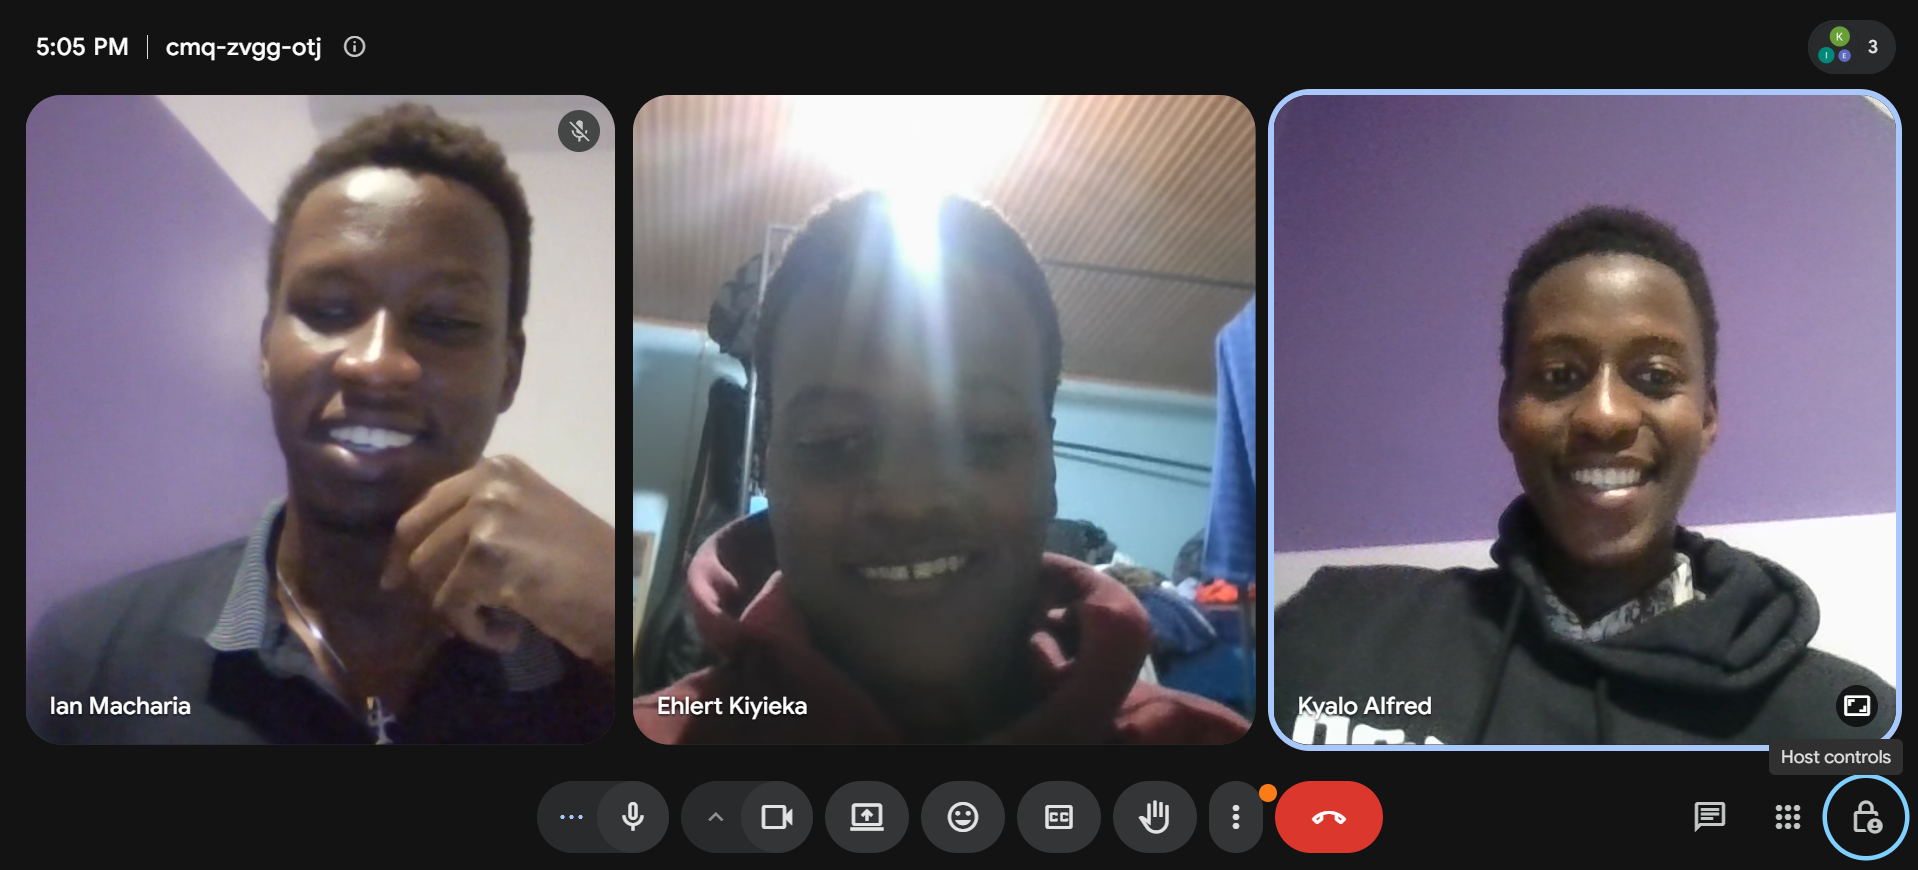